In [41]:
import matplotlib
import numpy as np
import pandas as pd
from narwhals import Int64
import seaborn as sns
from scipy.special.cython_special import stdtrit
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import make_scorer, brier_score_loss
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
import matplotlib.pyplot as plt
from sklearn.base import clone
from scipy import special

In [95]:
train_df = pd.read_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\cleaned_data\stop_search_test1.csv", index_col=0)

# Preprocessing before pipeline and modeling
## We drop unnecessary columns, define categorical and discrete/numerical columns for imputation, and convert categorical variables into strings

In [96]:
# Dropping unnecessary columns for modeling
train_date = train_df["event_dt"]
train_df = train_df.drop(["event_dt", "orig_age", "vital_flag", "orig_height", "orig_weight", "BMI", "year", "Zone", "Latitude", "Longitude", "SubjectID"], axis = 1)

# Unfloating zip code
train_df["Zip"] = train_df["Zip"].astype("Int64")
# Defining categorical columns
cat_cols = ["SubjectRace", "Zip", "District", "StopDescription"]
# Defining discrete/numerical columns
dis_cols = ["SubjectGender", "SubjectAge", "SubjectHeight", "SubjectWeight", "VehicleYear", "SubjectHasPhotoID", "hour", "night", "isDriver"]
# Numerical columns we would like to scale
scale_cols = ["SubjectAge", "SubjectHeight", "SubjectWeight", "VehicleYear", "hour"]
# Binary columns
bin_cols = ["SubjectGender", "SubjectHasPhotoID", "night", "isDriver"]

# Converting variables into strings
train_df[cat_cols] = train_df[cat_cols].astype(str)

In [97]:
target = "search_occurred"
X_train = train_df.drop([target], axis = 1)[cat_cols + dis_cols]
y_train = train_df[target]

# Defining classes to build pipeline
## CatBinner groups sparse labels in categorical variables in an Other category. RoundImputed is used after imputation, to ensure imputed numerical values are discrete

In [77]:
class CatBinner(BaseEstimator, TransformerMixin):
    def __init__(self, cols, min_freq=0.01, fill_value="Other"):
        self.cols = cols
        self.min_freq = min_freq
        self.fill_value = fill_value

    def fit(self, X, y=None):
        self.keep_labels = {}
        for c in self.cols:
            freq = X[c].value_counts(normalize=True)
            self.keep_labels[c] = freq[freq >= self.min_freq].index.tolist()

        return self

    def transform(self, X):
        X_copy = X.copy()
        for c in self.cols:
            labels = self.keep_labels[c]
            X_copy[c] = np.where(X_copy[c].isin(labels) | X_copy[c].isna(), X_copy[c], self.fill_value)
        return X_copy

    def set_output(self, *, transform=None):
        return self

class RoundImputed(BaseEstimator, TransformerMixin):
    def __init__(self, cols):
        self.cols = cols

    def fit(self, X, y=None):
        rounded = X[self.cols].round()
        self.min_ = rounded.min()
        self.max_ = rounded.max()
        return self

    def transform(self, X):
        X_copy = X.copy()
        X_copy[self.cols] = X_copy[self.cols].round().clip(self.min_, self.max_, axis=1)
        return X_copy

    def set_output(self, *, transform=None):
        return self

class OrdEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols, inner):
        self.cat_cols = cat_cols
        self.inner = inner

    def _encode(self, X):
        X_enc = X.copy()
        X_enc[self.cat_cols] = self.encoder_.transform(X[self.cat_cols])
        return X_enc

    def _decode(self, X_imp):
        X_dec = X_imp.copy()
        X_dec[self.cat_cols] = self.encoder_.inverse_transform(X_imp[self.cat_cols])
        return X_dec

    def fit_transform(self, X, y=None):
        self.encoder_ = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan)
        self.encoder_.fit(X[self.cat_cols])
        self.inner_ = clone(self.inner)
        return self._decode(self.inner_.fit_transform(self._encode(X), y))

    def fit(self, X, y=None):
        self.fit_transform(X, y)
        return self

    def transform(self, X):
        return self._decode(self.inner_.transform(self._encode(X)))

    def set_output(self, *, transform=None):
        return self

# Building pipeline
## Define a function to construct pipeline given model, and discrete and categorical columns

In [78]:
def build_pipeline(model, cat_cols, dis_cols, scale_cols):
    imputer = IterativeImputer(estimator=HistGradientBoostingRegressor(max_iter=50, random_state=10), skip_complete=True, max_iter=5, tol=1e-2, random_state=10)

    impute = Pipeline([
        ("imputer", imputer),
        ("round", RoundImputed(cols=cat_cols + dis_cols)),
    ])

    impute.set_output(transform="pandas")

    encode = ColumnTransformer([("encode", OneHotEncoder(handle_unknown="ignore"), cat_cols), ("scale", StandardScaler(), scale_cols)], remainder="passthrough", verbose_feature_names_out=False)

    pipeline = Pipeline([
        ("bin", CatBinner(cols=cat_cols, min_freq=0.01, fill_value="Other")),
        ("imputer", OrdEncoder(cat_cols, impute)),
        ("encode", encode),
        ("model", model)
    ], memory="cache_dir")

    return pipeline

## Defining ECE scorer

In [98]:
def expected_calibration_error(y_true, y_prob, n_bins=20):
    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    ece = 0.0
    for i in range(n_bins):
        bin_mask = (y_prob >= bin_edges[i]) & (y_prob <= bin_edges[i + 1])
        if np.any(bin_mask):
            bin_accuracy = np.mean(y_true[bin_mask])
            bin_confidence = bin_centers[i]
            ece += np.abs(bin_confidence - bin_accuracy) * np.sum(bin_mask)
    ece /= y_true.size
    return ece

ece = make_scorer(expected_calibration_error, greater_is_better=False, response_method="predict_proba", n_bins = 20)

# Modeling
## Logistic regression

In [99]:
# USE OPTIMAL PARAMETERS FOUND IN TUNING
lr = LogisticRegression(l1_ratio=1, C = 0.004832930238571752, max_iter = 1000, random_state=10, solver="saga")

pipeline = build_pipeline(lr, cat_cols, dis_cols, scale_cols)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=10)

lr_cross_val_scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring={"average_precision":"average_precision", "roc_auc":"roc_auc", "neg_brier_score":"neg_brier_score", "neg_ece":ece}, return_train_score=True, error_score="raise", verbose=2)

[CV] END .................................................... total time=   2.2s
[CV] END .................................................... total time=   2.0s
[CV] END .................................................... total time=   2.1s
[CV] END .................................................... total time=   5.9s
[CV] END .................................................... total time=   3.9s
[CV] END .................................................... total time=   3.2s
[CV] END .................................................... total time=   3.3s
[CV] END .................................................... total time=   3.5s
[CV] END .................................................... total time=   6.4s
[CV] END .................................................... total time=   3.9s


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:   42.9s finished


## Decision Tree

In [100]:
dt = DecisionTreeClassifier(criterion = "entropy", max_depth = 9, min_samples_leaf = 31, min_samples_split = 29, random_state=10)

pipeline = build_pipeline(dt, cat_cols, dis_cols, scale_cols)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=10)

dt_cross_val_scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring={"average_precision":"average_precision", "roc_auc":"roc_auc", "neg_brier_score":"neg_brier_score", "neg_ece":ece}, return_train_score=True, error_score="raise", verbose=2)

[CV] END .................................................... total time=   0.3s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.3s
[CV] END .................................................... total time=   0.3s
[CV] END .................................................... total time=   0.3s


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:    5.4s finished


## Random Forest

In [101]:
rf = RandomForestClassifier(criterion="gini", max_depth=None, min_samples_split=13, min_samples_leaf=11, max_features="log2", random_state=10)

pipeline = build_pipeline(rf, cat_cols, dis_cols, scale_cols)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=10)

rf_cross_val_scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring={"average_precision":"average_precision", "roc_auc":"roc_auc", "neg_brier_score":"neg_brier_score", "neg_ece":ece}, return_train_score=True, error_score="raise", verbose=2)

[CV] END .................................................... total time=   9.2s
[CV] END .................................................... total time=  11.6s
[CV] END .................................................... total time=  12.1s
[CV] END .................................................... total time=  12.3s
[CV] END .................................................... total time=  10.0s
[CV] END .................................................... total time=   9.9s
[CV] END .................................................... total time=  12.3s
[CV] END .................................................... total time=  11.8s
[CV] END .................................................... total time=  12.4s
[CV] END .................................................... total time=  12.0s


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:  2.1min finished


# Evaluating metrics

In [102]:
# Saving results
lr_scores = pd.DataFrame(lr_cross_val_scores)
dt_scores = pd.DataFrame(dt_cross_val_scores)
rf_scores = pd.DataFrame(rf_cross_val_scores)

# Making brier and ece nonnegative
lr_scores["test_brier_score"], lr_scores["train_brier_score"], lr_scores["test_ece"], lr_scores["train_ece"] = -lr_scores["test_neg_brier_score"], -lr_scores["train_neg_brier_score"], -lr_scores["test_neg_ece"], -lr_scores["train_neg_ece"]

dt_scores["test_brier_score"], dt_scores["train_brier_score"], dt_scores["test_ece"], dt_scores["train_ece"] = -dt_scores["test_neg_brier_score"], -dt_scores["train_neg_brier_score"], -dt_scores["test_neg_ece"], -dt_scores["train_neg_ece"]

rf_scores["test_brier_score"], rf_scores["train_brier_score"], rf_scores["test_ece"], rf_scores["train_ece"] = -rf_scores["test_neg_brier_score"], -rf_scores["train_neg_brier_score"], -rf_scores["test_neg_ece"], -rf_scores["train_neg_ece"]

# Creating standard deviation and error columns
t_alpha = special.stdtrit(len(lr_scores)-1, 0.975)
summary_lr = (lr_scores.agg(["mean", "std"]).T.reset_index())
summary_lr.columns = ["metric", "lr_mean", "lr_std"]
summary_lr["lr_se"] = summary_lr["lr_std"]/np.sqrt(len(lr_scores))
summary_lr["lr_lower_95_ci"] = summary_lr["lr_mean"] - t_alpha*summary_lr["lr_se"]
summary_lr["lr_upper_95_ci"] = summary_lr["lr_mean"] + t_alpha*summary_lr["lr_se"]

summary_dt = (dt_scores.agg(["mean", "std"]).T.reset_index())
summary_dt.columns = ["metric", "dt_mean", "dt_std"]
summary_dt["dt_se"] = summary_dt["dt_std"]/np.sqrt(len(dt_scores))
summary_dt["dt_lower_95_ci"] = summary_dt["dt_mean"] - t_alpha*summary_dt["dt_se"]
summary_dt["dt_upper_95_ci"] = summary_dt["dt_mean"] + t_alpha*summary_dt["dt_se"]

summary_rf = (rf_scores.agg(["mean", "std"]).T.reset_index())
summary_rf.columns = ["metric", "rf_mean", "rf_std"]
summary_rf["rf_se"] = summary_rf["rf_std"]/np.sqrt(len(rf_scores))
summary_rf["rf_lower_95_ci"] = summary_rf["rf_mean"] - t_alpha*summary_rf["rf_se"]
summary_rf["rf_upper_95_ci"] = summary_rf["rf_mean"] + t_alpha*summary_rf["rf_se"]

In [103]:
# Combining results into dataframe
score_summary = pd.concat([summary_lr, summary_dt, summary_rf], axis=1)
# Drop duplicate metric columns
score_summary = score_summary.T.drop_duplicates().T
score_summary

,metric,lr_mean,lr_std,lr_se,lr_lower_95_ci,lr_upper_95_ci,dt_mean,dt_std,dt_se,dt_lower_95_ci,dt_upper_95_ci,rf_mean,rf_std,rf_se,rf_lower_95_ci,rf_upper_95_ci
0,fit_time,3.517965,1.468911,0.46451,2.467169,4.56876,0.264756,0.018184,0.00575,0.251748,0.277764,11.230918,1.198483,0.378993,10.373575,12.08826
1,score_time,0.2166,0.048458,0.015324,0.181935,0.251264,0.06773,0.009914,0.003135,0.060638,0.074823,0.228829,0.059184,0.018716,0.186491,0.271167
2,test_average_precision,0.208249,0.023523,0.007439,0.191422,0.225077,0.211757,0.023912,0.007562,0.194651,0.228862,0.259048,0.030813,0.009744,0.237006,0.28109
3,train_average_precision,0.202708,0.003325,0.001051,0.200329,0.205086,0.286005,0.003066,0.00097,0.283812,0.288199,0.436069,0.005473,0.001731,0.432154,0.439985
4,test_roc_auc,0.756705,0.028559,0.009031,0.736275,0.777134,0.767313,0.018889,0.005973,0.753801,0.780826,0.813498,0.02113,0.006682,0.798382,0.828613
5,train_roc_auc,0.758023,0.00434,0.001373,0.754918,0.761128,0.847875,0.001727,0.000546,0.84664,0.84911,0.929838,0.001411,0.000446,0.928829,0.930848
6,test_neg_brier_score,-0.048622,0.00042,0.000133,-0.048923,-0.048322,-0.047826,0.001032,0.000326,-0.048564,-0.047088,-0.046194,0.000863,0.000273,-0.046812,-0.045577
7,train_neg_brier_score,-0.048583,0.000108,0.000034,-0.04866,-0.048506,-0.044447,0.000064,0.00002,-0.044493,-0.0444,-0.041862,0.000119,0.000038,-0.041947,-0.041777
8,test_neg_ece,-0.013734,0.002697,0.000853,-0.015663,-0.011805,-0.012479,0.002347,0.000742,-0.014158,-0.0108,-0.011462,0.003284,0.001038,-0.013811,-0.009113
9,train_neg_ece,-0.012466,0.000145,0.000046,-0.01257,-0.012362,-0.009621,0.000967,0.000306,-0.010313,-0.008929,-0.033985,0.001495,0.000473,-0.035054,-0.032916


In [104]:
# Saving results
summary_lr.to_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\modeling_results\lr_cross_val_scores.csv", index=False)
summary_dt.to_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\modeling_results\dt_cross_val_scores.csv", index=False)
summary_rf.to_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\modeling_results\rf_cross_val_scores.csv", index=False)
score_summary.to_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\modeling_results\model_cross_val_scores.csv", index=False)

## Plotting cross validation scores

In [105]:
lr_scores["Model"] = "Logistic Regression"
dt_scores["Model"] = "Decision Tree"
rf_scores["Model"] = "Random Forest"
scores = pd.concat([lr_scores, dt_scores, rf_scores])
scores

,fit_time,score_time,test_average_precision,train_average_precision,test_roc_auc,train_roc_auc,test_neg_brier_score,train_neg_brier_score,test_neg_ece,train_neg_ece,test_brier_score,train_brier_score,test_ece,train_ece,Model
0,2.113412,0.232201,0.249646,0.198135,0.810263,0.754343,-0.047821,-0.048772,-0.019428,-0.012581,0.047821,0.048772,0.019428,0.012581,Logistic Regression
1,1.947054,0.120319,0.193945,0.204801,0.734631,0.759027,-0.048829,-0.048525,-0.012488,-0.012641,0.048829,0.048525,0.012488,0.012641,Logistic Regression
2,2.020873,0.152914,0.194614,0.204113,0.745860,0.759658,-0.049020,-0.048516,-0.012685,-0.012438,0.049020,0.048516,0.012685,0.012438,Logistic Regression
3,5.738748,0.251886,0.230183,0.200760,0.777608,0.756975,-0.048241,-0.048682,-0.014350,-0.012557,0.048241,0.048682,0.014350,0.012557,Logistic Regression
4,3.708442,0.248286,0.201901,0.202176,0.752554,0.758222,-0.048575,-0.048584,-0.012867,-0.012394,0.048575,0.048584,0.012867,0.012394,Logistic Regression
5,3.034017,0.233155,0.164960,0.209322,0.724035,0.763167,-0.049348,-0.048389,-0.010345,-0.012500,0.049348,0.048389,0.010345,0.012500,Logistic Regression
6,3.251097,0.176620,0.209184,0.202298,0.739329,0.759823,-0.048603,-0.048585,-0.014565,-0.012420,0.048603,0.048585,0.014565,0.012420,Logistic Regression
7,3.403865,0.245480,0.229359,0.198099,0.788497,0.747752,-0.048439,-0.048688,-0.013147,-0.012195,0.048439,0.048688,0.013147,0.012195,Logistic Regression
8,6.239941,0.249351,0.203052,0.204419,0.726523,0.761719,-0.048550,-0.048549,-0.016625,-0.012631,0.048550,0.048549,0.016625,0.012631,Logistic Regression
9,3.722198,0.255787,0.205651,0.202953,0.767747,0.759543,-0.048796,-0.048541,-0.010839,-0.012299,0.048796,0.048541,0.010839,0.012299,Logistic Regression


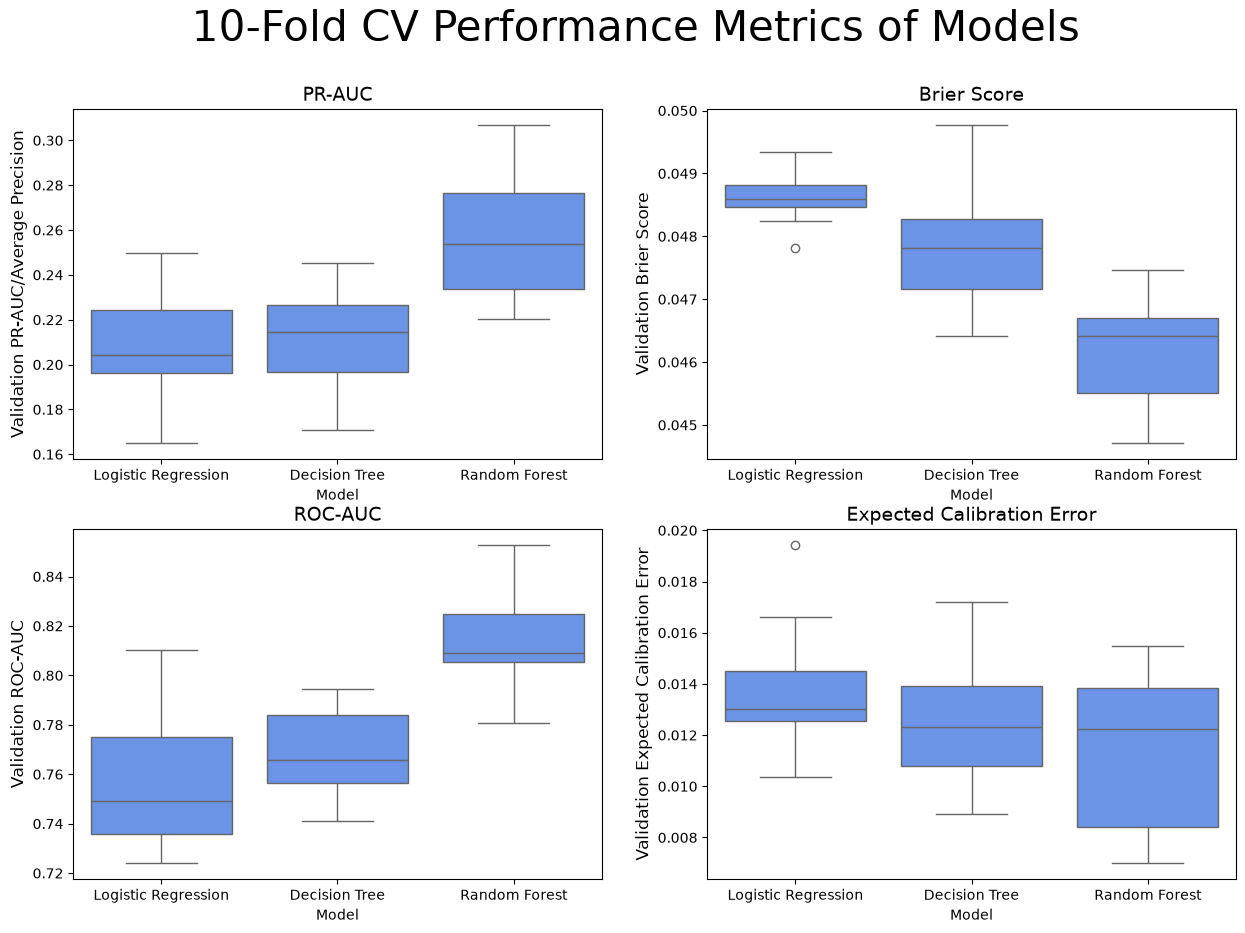

In [108]:
fig, axs = plt.subplots(2,2, figsize=(15,10))

sns.boxplot(scores, x = "Model", y = "test_average_precision", order=["Logistic Regression", "Decision Tree", "Random Forest"], ax = axs[0,0])
axs[0,0].set_ylabel("Validation PR-AUC/Average Precision", fontsize=12)
axs[0,0].set_title("PR-AUC", fontsize=14)

sns.boxplot(scores, x = "Model", y = "test_brier_score", order=["Logistic Regression", "Decision Tree", "Random Forest"], ax = axs[0,1])
axs[0,1].set_ylabel("Validation Brier Score", fontsize=12)
axs[0,1].set_title("Brier Score", fontsize=14)

sns.boxplot(scores, x = "Model", y = "test_roc_auc", order=["Logistic Regression", "Decision Tree", "Random Forest"], ax = axs[1,0])
axs[1,0].set_ylabel("Validation ROC-AUC", fontsize=12)
axs[1,0].set_title("ROC-AUC", fontsize=14)

sns.boxplot(scores, x = "Model", y = "test_ece", order=["Logistic Regression", "Decision Tree", "Random Forest"], ax = axs[1,1])
axs[1,1].set_ylabel("Validation Expected Calibration Error", fontsize=12)
axs[1,1].set_title("Expected Calibration Error", fontsize=14)

plt.suptitle("10-Fold CV Performance Metrics of Models", fontsize=30)
plt.savefig(r"C:\Users\gelet\PycharmProjects\stop-and-search\plots\cv_models_boxplot.png", bbox_inches="tight")
plt.show()